<a href="https://colab.research.google.com/github/LauraSeeling/PR1_Proteomics-/blob/main/AlternativesMethods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# "raw.githubusercontent.com" serves the file itself; the normal github.com
# "blob" link serves a web page, which pandas can't read.
DATA_URL = ("https://raw.githubusercontent.com/LauraSeeling/"
            "PR1_Proteomics-/main/PR1_heart_valve_disease.xlsx")

OUT_DIR = Path("qc_tables")         # processed tables are saved here
OUT_DIR.mkdir(exist_ok=True)

FIRST_INTENSITY_COL = 15            # column P (0-based index 15)
FILTER_COLS = ["Potential contaminant", "Reverse", "Only identified by site"]
MIN_VALID_FRACTION = 0.60           # keep proteins with >= 60 % values in >= 1 group
MIN_PEPTIDES = 2                    # proteins with fewer razor+unique peptides are flagged
IMPUTE_DOWNSHIFT = 1.8              # Perseus imputation: shift down (in SD)
IMPUTE_WIDTH = 0.3                  # Perseus imputation: width (x SD)

# Order in which groups appear in plots (controls first, then disease)
GROUP_ORDER = ["control (donor heart)", "aortic stenosis", "mitral regurgitation"]
GROUP_COLORS = {
    "control (donor heart)": "#009E73",
    "aortic stenosis": "#D55E00",
    "mitral regurgitation": "#0072B2",
}

SEX_MARKERS = {"male": "o", "female": "^"}      # circle / triangle in PCA
SEX_COLORS = {"male": "#404040", "female": "#C8C8C8"}  # heatmap colour bar

sns.set_theme(style="whitegrid", context="notebook")


def show(fig):
    """Tidy the layout and show the figure."""
    fig.tight_layout()
    plt.show()

In [ ]:
raw = pd.read_excel(DATA_URL, sheet_name="proteinGroups")
samples = pd.read_excel(DATA_URL, sheet_name="samples")

print(f"Loaded {raw.shape[0]} protein groups x {raw.shape[1]} columns")
print(samples["group"].value_counts(), "\n")

Loaded 9782 protein groups x 90 columns
group
aortic stenosis          41
control (donor heart)    17
mitral regurgitation     17
Name: count, dtype: int64 



In [ ]:
is_flagged = raw[FILTER_COLS].eq("+").any(axis=1)
for col in FILTER_COLS:
    print(f"{col:<25} '+': {raw[col].eq('+').sum()}")

# Fragments: lead entry = first entry of the semicolon-separated FASTA headers
lead_header = raw["Fasta headers"].fillna("").str.split(";").str[0]
is_fragment = lead_header.str.contains("Fragment", case=False)
print(f"{'Fragment (lead entry)':<25}    : {is_fragment.sum()}")

is_flagged = is_flagged | is_fragment
df = raw.loc[~is_flagged].reset_index(drop=True)
print(f"\nRemoved {is_flagged.sum()} protein groups (categories overlap) "
      f"-> {len(df)} remain")

Potential contaminant     '+': 83
Reverse                   '+': 247
Only identified by site   '+': 1284
Fragment (lead entry)        : 733

Removed 1840 protein groups (categories overlap) -> 7942 remain


In [ ]:
intensity_cols = df.columns[FIRST_INTENSITY_COL:]
intens = df[intensity_cols].astype(float)
intens.index = df["Gene names"].fillna(df["Majority protein IDs"])
intens.columns = [c.replace("LFQ intensity ", "") for c in intensity_cols]

meta = samples.set_index("sample").loc[intens.columns]
sample_colors = meta["group"].map(GROUP_COLORS)

In [ ]:
intens_nan = intens.replace(0, np.nan)
log2_all = np.log2(intens_nan)

n_missing = intens_nan.isna().sum().sum()
print(f"Zeros replaced by NaN: {n_missing} "
      f"({100 * n_missing / intens_nan.size:.1f}% of all values)")

Zeros replaced by NaN: 304113 (51.1% of all values)


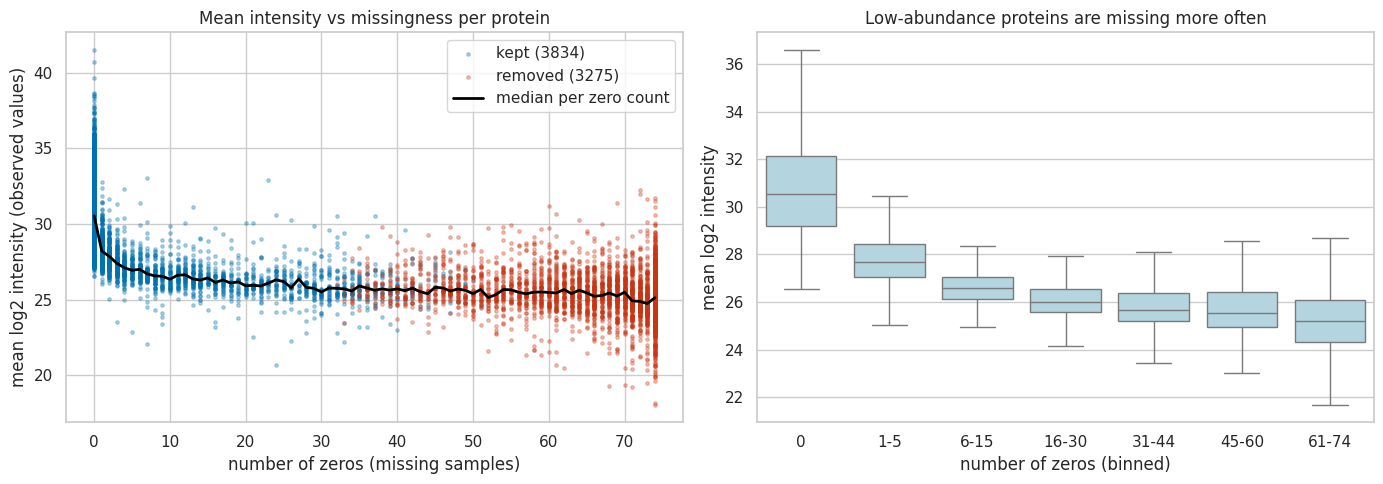

Spearman r (mean intensity vs zeros): -0.781


In [ ]:
# Same rule as the filter in the next section, computed here for colouring
valid_frac_by_group = pd.DataFrame({
    g: intens_nan[meta.index[meta["group"] == g]].notna().mean(axis=1)
    for g in GROUP_ORDER})
passes_filter = (valid_frac_by_group >= MIN_VALID_FRACTION).any(axis=1)

protein_qc = pd.DataFrame({
    "mean_log2": log2_all.mean(axis=1),       # mean of observed values only
    "n_zeros": intens_nan.isna().sum(axis=1),
    "kept": passes_filter,
}).dropna(subset=["mean_log2"])               # drop never-observed proteins

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for kept, colour, label in [(True, "#0072B2", "kept"), (False, "#CC3311", "removed")]:
    sub = protein_qc[protein_qc["kept"] == kept]
    axes[0].scatter(sub["n_zeros"], sub["mean_log2"], s=6, alpha=0.3,
                    color=colour, label=f"{label} ({len(sub)})")
trend = protein_qc.groupby("n_zeros")["mean_log2"].median()
axes[0].plot(trend.index, trend.values, color="black", lw=2,
             label="median per zero count")
axes[0].set_xlabel("number of zeros (missing samples)")
axes[0].set_ylabel("mean log2 intensity (observed values)")
axes[0].set_title("Mean intensity vs missingness per protein")
axes[0].legend()

bins = pd.cut(protein_qc["n_zeros"], bins=[-1, 0, 5, 15, 30, 44, 60, 75],
              labels=["0", "1-5", "6-15", "16-30", "31-44", "45-60", "61-74"])
sns.boxplot(x=bins, y=protein_qc["mean_log2"], ax=axes[1],
            color="lightblue", showfliers=False)
axes[1].set_xlabel("number of zeros (binned)")
axes[1].set_ylabel("mean log2 intensity")
axes[1].set_title("Low-abundance proteins are missing more often")
show(fig)
print("Spearman r (mean intensity vs zeros):",
      round(protein_qc[["mean_log2", "n_zeros"]].corr(method="spearman").iloc[0, 1], 3))

In [ ]:
keep = passes_filter.to_numpy()
log2 = log2_all.loc[keep]
intens_kept = intens_nan.loc[keep]
df_kept = df.loc[keep].reset_index(drop=True)
never_seen = intens_nan.isna().all(axis=1).sum()
print(f"Kept {keep.sum()} proteins, removed {(~keep).sum()} "
      f"({never_seen} of them were never detected in any sample)")
print(f"Missing values left: {100 * log2.isna().mean().mean():.1f}%")

# Proteins that pass only because of ONE group (fewer than 60 % values in
# the other groups): these are candidates for group-specific proteins.
group_specific = valid_frac_by_group.loc[keep]
only_one = (group_specific >= MIN_VALID_FRACTION).sum(axis=1) == 1
print(f"\nProteins that pass in only one group: {only_one.sum()}")
print((group_specific.loc[only_one] >= MIN_VALID_FRACTION).idxmax(axis=1)
      .value_counts().rename("passing group").to_string())

Kept 3834 proteins, removed 4108 (833 of them were never detected in any sample)
Missing values left: 10.3%

Proteins that pass in only one group: 292
control (donor heart)    136
mitral regurgitation      83
aortic stenosis           73


In [ ]:
single_peptide = (df_kept["Razor + unique peptides"] < MIN_PEPTIDES).to_numpy()
protein_flags = pd.DataFrame({
    "Gene names": log2.index,
    "Razor + unique peptides": df_kept["Razor + unique peptides"].to_numpy(),
    "single_peptide": single_peptide,
    "missing_%": (100 * log2.isna().mean(axis=1)).round(1).to_numpy(),
    "median_log2": log2.median(axis=1).round(2).to_numpy(),
})
print(f"Proteins with < {MIN_PEPTIDES} razor+unique peptides: "
      f"{single_peptide.sum()} of {len(single_peptide)}")
print("Median % missing values: "
      f"{protein_flags.loc[single_peptide, 'missing_%'].median():.1f}% (single peptide) vs "
      f"{protein_flags.loc[~single_peptide, 'missing_%'].median():.1f}% (others)")
protein_flags.loc[single_peptide].sort_values("median_log2", ascending=False).head(10)

Proteins with < 2 razor+unique peptides: 79 of 3834
Median % missing values: 26.7% (single peptide) vs 1.3% (others)


,Gene names,Razor + unique peptides,single_peptide,missing_%,median_log2
1423,ATP5F1A,1,True,0.0,33.81
738,LDB3,1,True,0.0,31.20
2061,OGDH,1,True,28.0,31.02
601,UQCR11,1,True,0.0,30.90
1284,ATP2A2,1,True,0.0,29.86
623,NDUFA1,1,True,4.0,29.39
1979,TMSB10,1,True,4.0,28.79
2261,FLNC,1,True,14.7,28.66
312,IMMT,1,True,2.7,28.49
2884,TTN,1,True,0.0,28.42


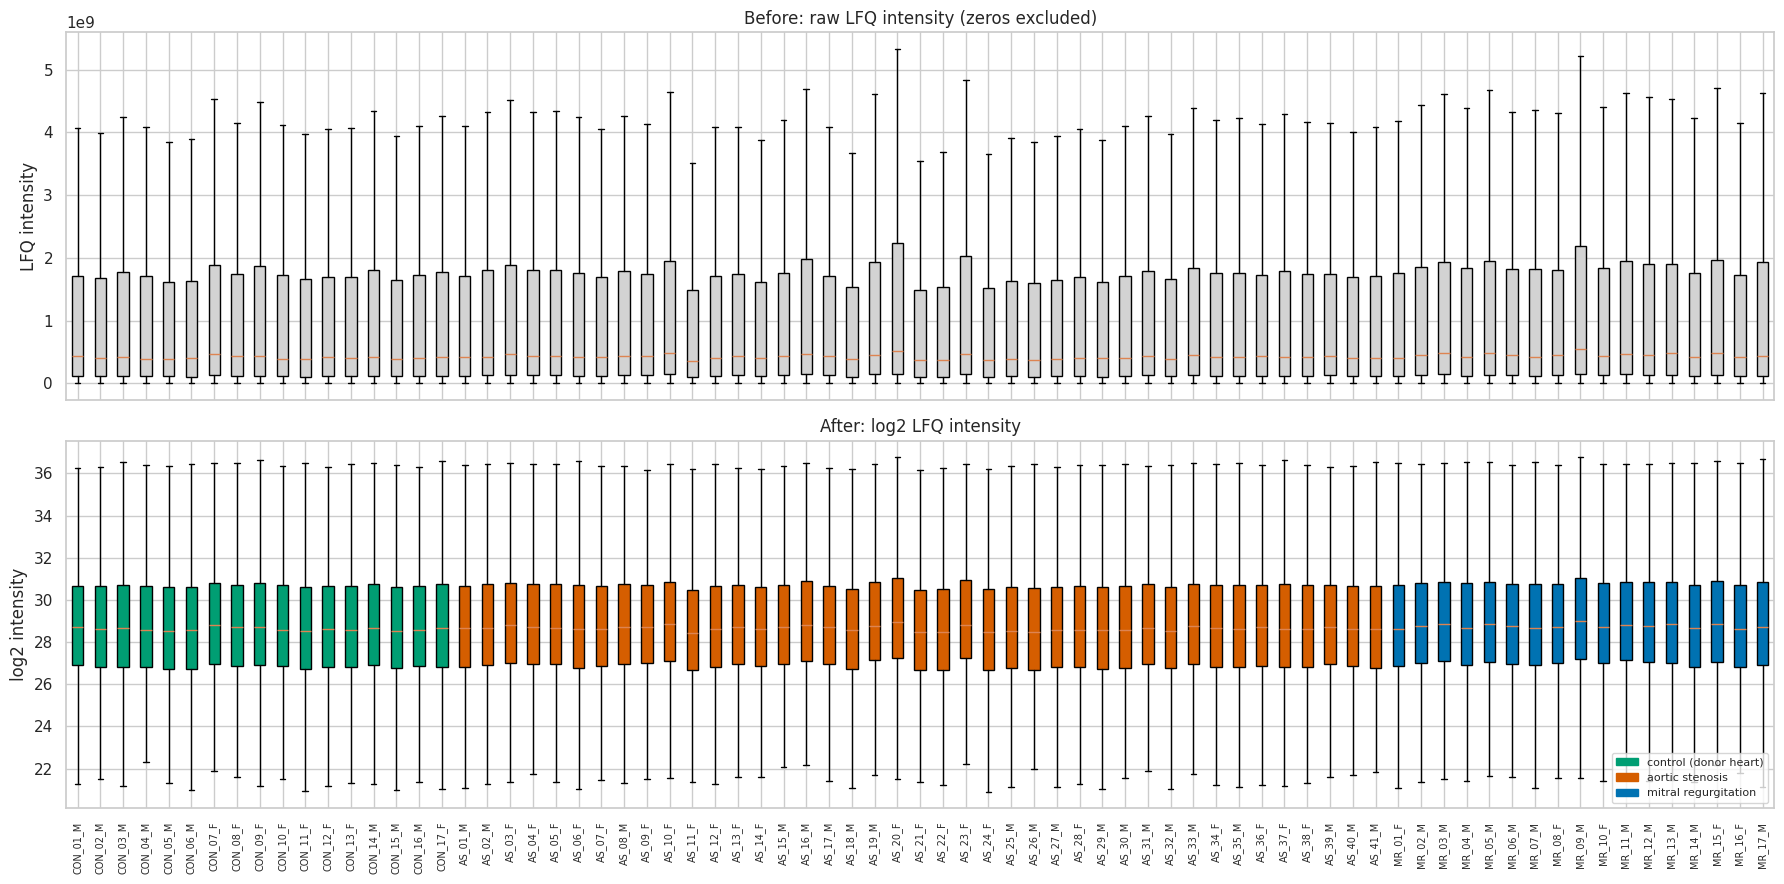

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(18, 9), sharex=True)
# samples sorted by group (control -> AS -> MR), then by name within group
order = meta.assign(g=pd.Categorical(meta["group"], GROUP_ORDER),
                    name=meta.index) \
            .sort_values(["g", "name"]).index

axes[0].boxplot([intens_kept[c].dropna() for c in order],
                showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="lightgrey"))
axes[0].set_title("Before: raw LFQ intensity (zeros excluded)")
axes[0].set_ylabel("LFQ intensity")

bp = axes[1].boxplot([log2[c].dropna() for c in order],
                     showfliers=False, patch_artist=True)
for patch, s in zip(bp["boxes"], order):
    patch.set_facecolor(sample_colors[s])
axes[1].set_title("After: log2 LFQ intensity")
axes[1].set_ylabel("log2 intensity")
axes[1].set_xticks(range(1, len(order) + 1))
axes[1].set_xticklabels(order, rotation=90, fontsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in GROUP_ORDER]
axes[1].legend(handles, GROUP_ORDER, loc="lower right", fontsize=8)
show(fig)

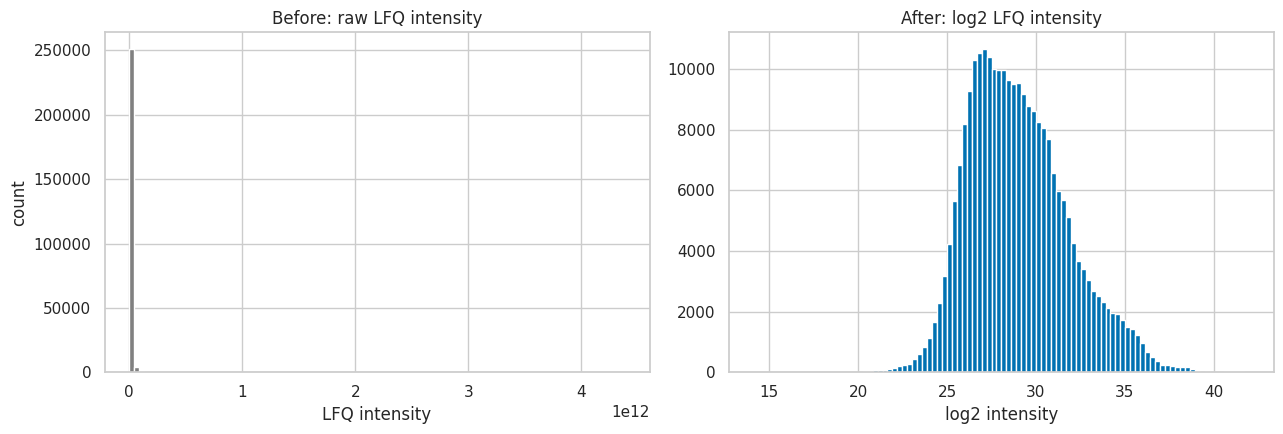

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(intens_kept.stack(), bins=100, color="grey")
axes[0].set_title("Before: raw LFQ intensity")
axes[0].set_xlabel("LFQ intensity")
axes[0].set_ylabel("count")

axes[1].hist(log2.stack(), bins=100, color="#0072B2")
axes[1].set_title("After: log2 LFQ intensity")
axes[1].set_xlabel("log2 intensity")
show(fig)

Medians computed on 1758 proteins found in all samples
Correction per sample: -0.24 to +0.64 log2 units
Largest corrections (log2 units added):
AS_23_F    0.64
AS_22_F    0.31
AS_14_F    0.28
AS_16_M    0.25
AS_21_F    0.25
dtype: float64


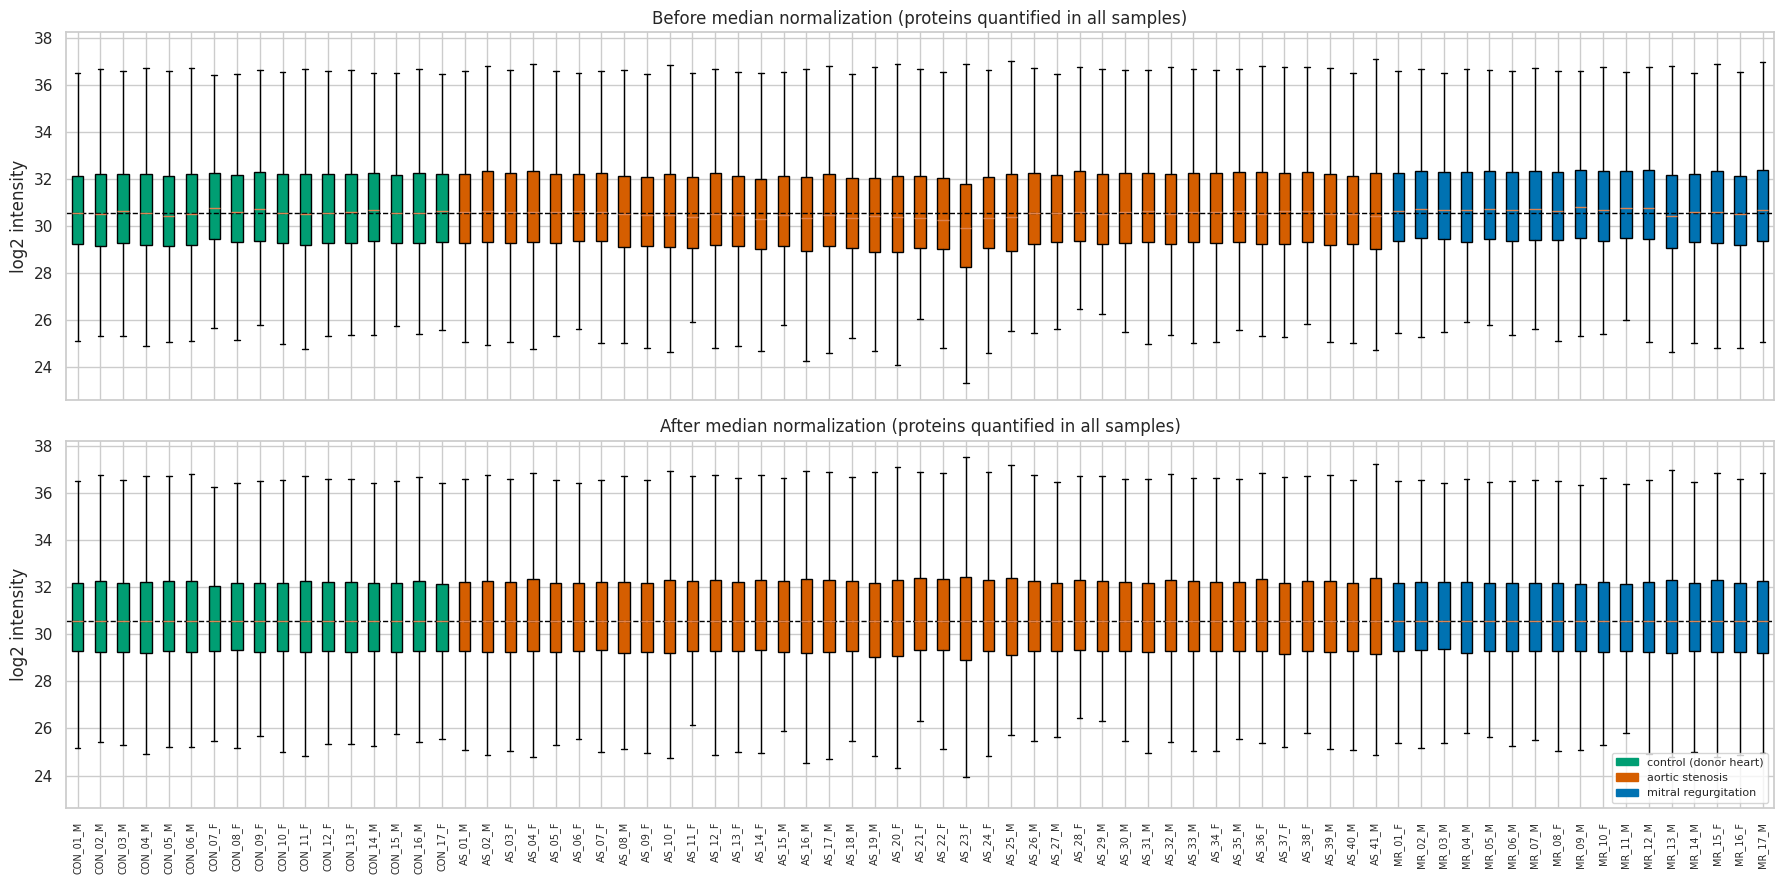

In [ ]:
complete_rows = log2.notna().all(axis=1)
sample_medians = log2.loc[complete_rows].median()
log2_unnorm = log2.copy()
log2 = log2 - sample_medians + sample_medians.median()

correction = sample_medians.median() - sample_medians   # added to each sample
print(f"Medians computed on {complete_rows.sum()} proteins found in all samples")
print(f"Correction per sample: {correction.min():+.2f} to "
      f"{correction.max():+.2f} log2 units")
print("Largest corrections (log2 units added):")
print(correction.loc[correction.abs().sort_values(ascending=False).index]
      .head(5).round(2))

# Boxes show the proteins found in all samples, i.e. the values the
# medians were computed on, so after normalization the medians line up.
fig, axes = plt.subplots(2, 1, figsize=(18, 9), sharex=True, sharey=True)
for ax, data, title in [
        (axes[0], log2_unnorm.loc[complete_rows], "Before median normalization"),
        (axes[1], log2.loc[complete_rows], "After median normalization")]:
    bp = ax.boxplot([data[c] for c in order],
                    showfliers=False, patch_artist=True)
    for patch, s in zip(bp["boxes"], order):
        patch.set_facecolor(sample_colors[s])
    ax.axhline(data.median().median(), color="black", ls="--", lw=1)
    ax.set_title(f"{title} (proteins quantified in all samples)")
    ax.set_ylabel("log2 intensity")
axes[1].set_xticks(range(1, len(order) + 1))
axes[1].set_xticklabels(order, rotation=90, fontsize=7)
axes[1].legend(handles, GROUP_ORDER, loc="lower right", fontsize=8)
show(fig)

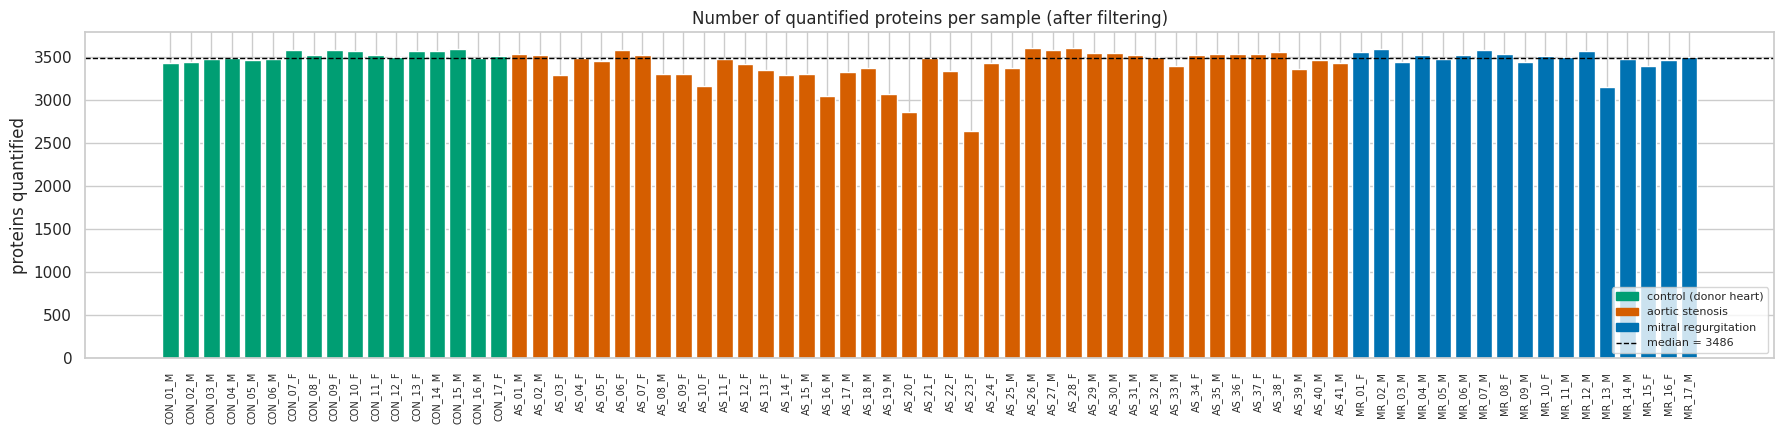

In [ ]:
n_ident = log2.notna().sum()[order]
fig, ax = plt.subplots(figsize=(18, 4.5))
ax.bar(n_ident.index, n_ident.values, color=sample_colors[order].values)
med_line = ax.axhline(n_ident.median(), color="black", ls="--", lw=1)
ax.set_ylabel("proteins quantified")
ax.set_title("Number of quantified proteins per sample "
             "(after filtering)")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.legend(handles + [med_line],
          GROUP_ORDER + [f"median = {n_ident.median():.0f}"],
          fontsize=8, loc="lower right")
show(fig)

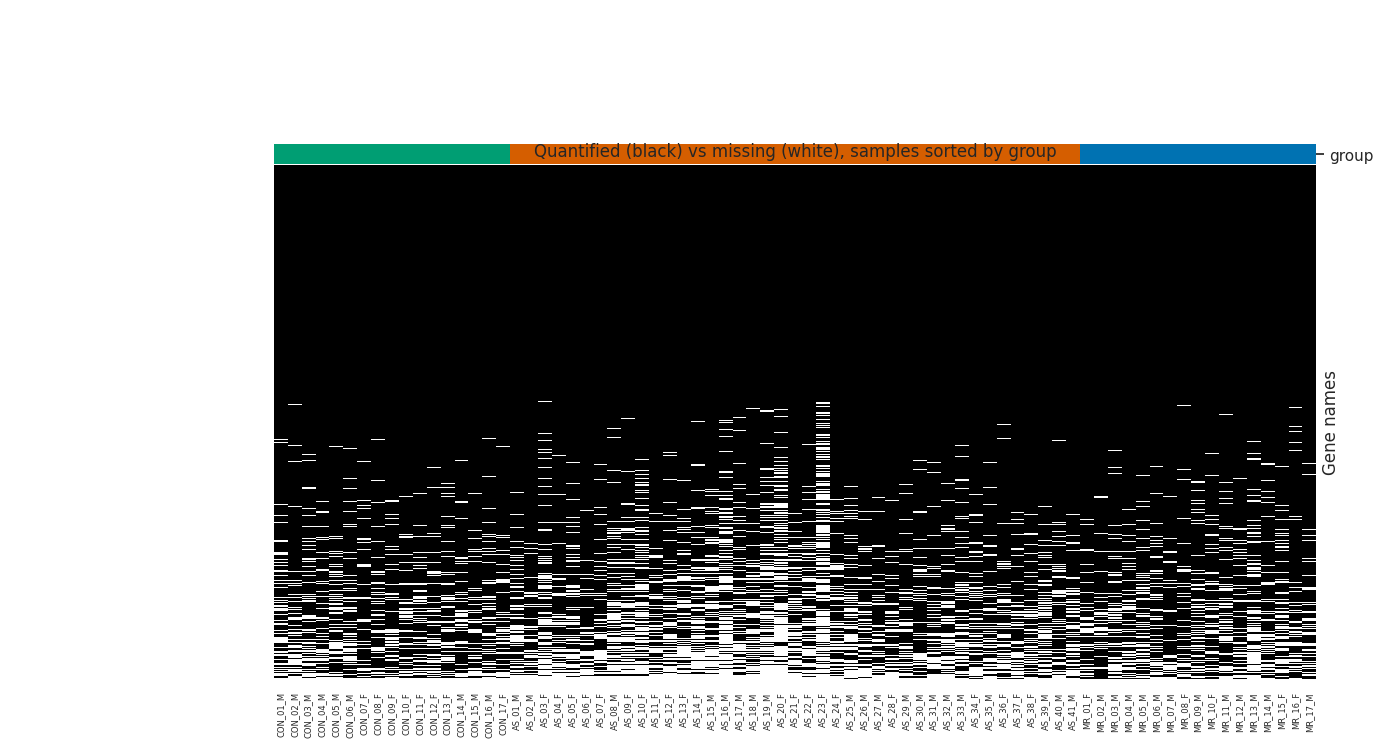

In [ ]:
miss = log2[order].notna()
miss = miss.iloc[np.argsort(-miss.sum(axis=1).to_numpy(), kind="stable")]
g = sns.clustermap(miss.astype(int), row_cluster=False, col_cluster=False,
                   col_colors=sample_colors[order], cmap="Greys",
                   yticklabels=False, xticklabels=True, figsize=(14, 8),
                   cbar_pos=None)
g.ax_heatmap.set_title("Quantified (black) vs missing (white), samples sorted by group")
g.ax_heatmap.tick_params(axis="x", labelsize=6)
plt.show()

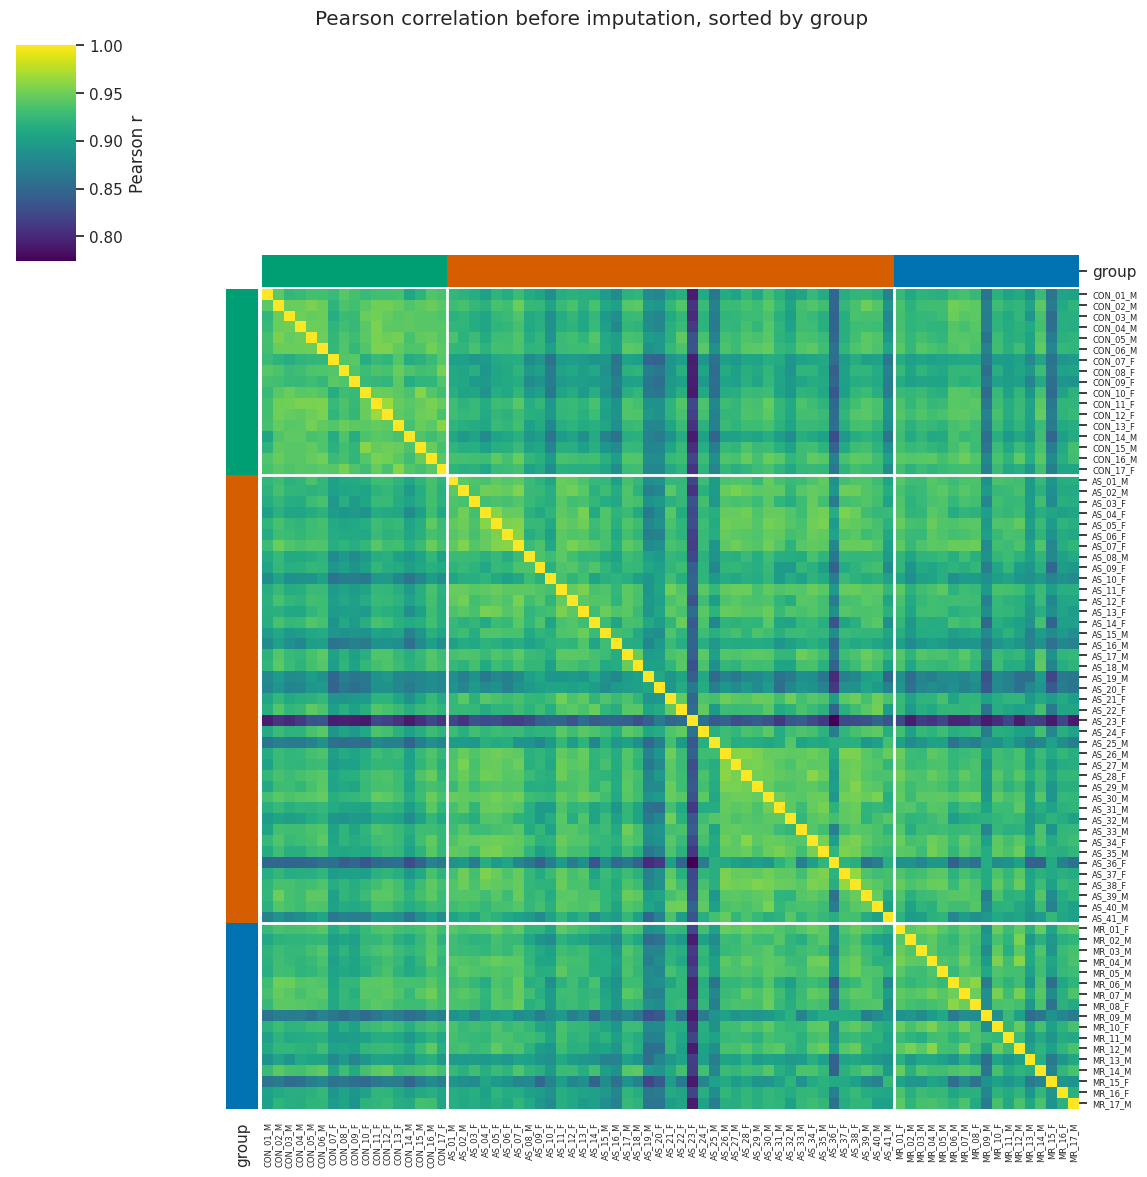

Lowest median correlation to other samples:
AS_23_F    0.822
AS_36_F    0.869
AS_19_M    0.880
MR_09_M    0.881
MR_15_F    0.883
dtype: float64


In [ ]:
corr = log2[order].corr(method="pearson", min_periods=50)
g = sns.clustermap(corr, cmap="viridis", row_cluster=False, col_cluster=False,
                   col_colors=sample_colors[order], row_colors=sample_colors[order],
                   figsize=(12, 12), xticklabels=True, yticklabels=True,
                   cbar_kws={"label": "Pearson r"})
group_sizes = meta.loc[order, "group"].value_counts().reindex(GROUP_ORDER)
for edge in np.cumsum(group_sizes.values)[:-1]:
    g.ax_heatmap.axhline(edge, color="white", lw=2)
    g.ax_heatmap.axvline(edge, color="white", lw=2)
g.ax_heatmap.tick_params(labelsize=6)
g.figure.suptitle("Pearson correlation before imputation, sorted by group", y=1.01)
plt.show()

median_corr = corr.where(~np.eye(len(corr), dtype=bool)).median()
print("Lowest median correlation to other samples:")
print(median_corr.nsmallest(5).round(3))

Imputed 29665 values (10.3% of the matrix)


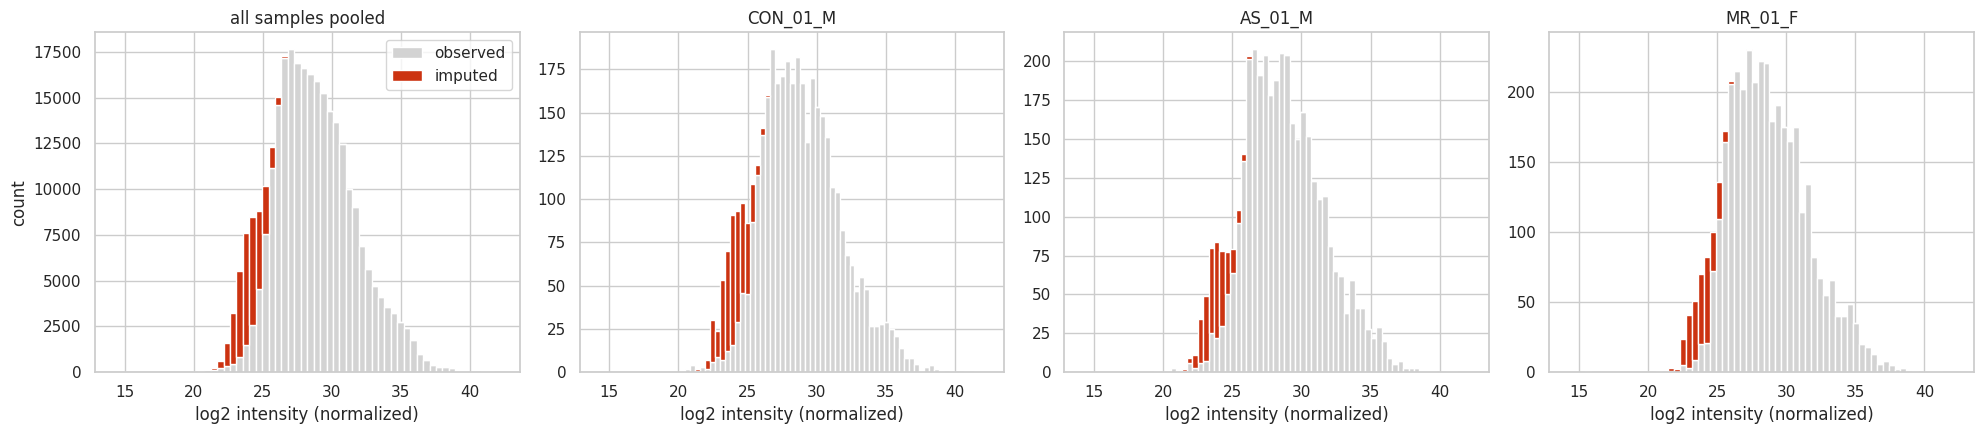

In [ ]:
rng = np.random.default_rng(seed=42)
log2_imp = log2.copy()
is_imputed = log2.isna()
for s in log2.columns:
    obs = log2[s].dropna()
    n_miss = is_imputed[s].sum()
    log2_imp.loc[is_imputed[s].to_numpy(), s] = rng.normal(
        loc=obs.mean() - IMPUTE_DOWNSHIFT * obs.std(),
        scale=IMPUTE_WIDTH * obs.std(),
        size=n_miss)
print(f"Imputed {is_imputed.sum().sum()} values "
      f"({100 * is_imputed.mean().mean():.1f}% of the matrix)")

# Plot: observed (grey) vs imputed (red) values, pooled and for one sample
# per group. Imputed values should sit at the lower tail of the observed
# distribution, not in the middle and not far below it.
examples = [meta.index[meta["group"] == g][0] for g in GROUP_ORDER]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharex=True)
for ax, (title, sel) in zip(axes, [("all samples pooled", list(log2.columns))]
                            + [(s, [s]) for s in examples]):
    observed = log2_imp[sel].where(~is_imputed[sel]).stack()
    imputed = log2_imp[sel].where(is_imputed[sel]).stack()
    ax.hist([observed, imputed], bins=60, stacked=True,
            color=["lightgrey", "#CC3311"], label=["observed", "imputed"])
    ax.set_title(title)
    ax.set_xlabel("log2 intensity (normalized)")
axes[0].set_ylabel("count")
axes[0].legend()
show(fig)

Missing values: 29665  of which MNAR-like (>=50% missing in the group): 8493 (29%)

Significant proteins (Mann-Whitney, BH < 0.05)
contrast           AS_vs_CON  MR_vs_CON
method                                 
Perseus (step 14)       1417        518
kNN                     1353        459
QRILC-style             1431        509
Mixed                   1584        714
Observed only           1295        459

...of which the protein is missing in >= 50% of a compared group
contrast           AS_vs_CON  MR_vs_CON
method                                 
Perseus (step 14)        109         32
kNN                       72         12
QRILC-style              121         31
Mixed                    270        170
Observed only             56          9

AS vs CON: agreement with the Perseus hits
method                shared  Perseus only  method only
kNN                     1260           157           93
QRILC-style             1385            32           46
Mixed                   1328   

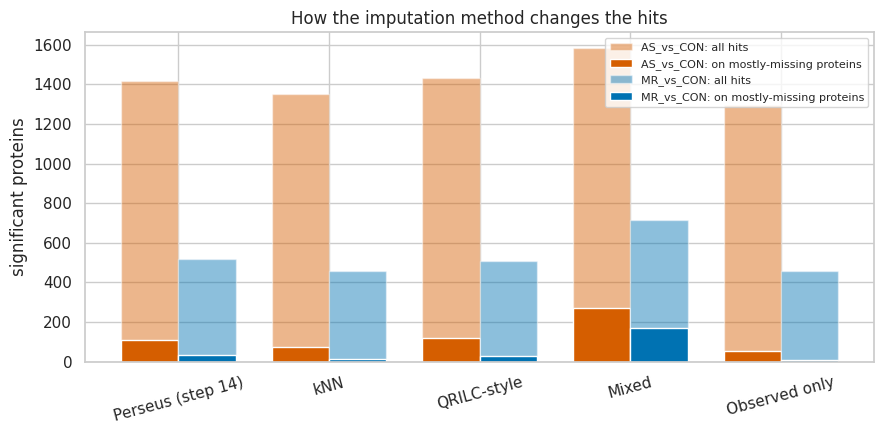

Saved qc_tables/imputation_comparison.csv


In [ ]:
# ==================================================================
# Imputation comparison for Google Colab (Python only, no R needed)
#
# HOW TO USE
#   1. Run the notebook from the top down to step 14 (imputation).
#   2. Paste this whole file into ONE new code cell and run it.
#
# Compares the Perseus-style imputation used in step 14 with:
#   - kNN            (assumes values are missing at random)
#   - QRILC-style    (left-censored: missing because below detection limit)
#   - mixed          (QRILC-style where a protein is mostly absent in a group,
#                     kNN for sporadic gaps)
#   - observed only  (no imputation; only proteins with >= 3 values per group)
# Each version goes through the same Mann-Whitney test + Benjamini-Hochberg.
# Needs: log2, meta, OUT_DIR, pd, np, plt  (from the earlier cells).
# ==================================================================
import warnings
from scipy import stats
from sklearn.impute import KNNImputer

warnings.filterwarnings("ignore", message="Mean of empty slice")

_missing = [n for n in ["log2", "meta", "OUT_DIR", "pd", "np", "plt"] if n not in globals()]
if _missing:
    raise RuntimeError(f"Run the notebook cells above first (missing: {_missing}).")

SEED = 42
FDR = 0.05
X = log2.to_numpy(dtype=float)                 # normalized, NaN kept
uid = pd.Index([f"p{i:05d}" for i in range(len(X))], name="protein")   # gene names repeat, so use unique IDs
cols = list(log2.columns)
grp = meta["group"].loc[cols].to_numpy()
GROUPS = {"AS": "aortic stenosis", "MR": "mitral regurgitation", "CON": "control (donor heart)"}


def bh(p):
    p = np.asarray(p, dtype=float)
    n = len(p)
    order_p = np.argsort(p)
    adj = np.empty(n)
    running = 1.0
    for rank, i in zip(range(n, 0, -1), order_p[::-1]):
        running = min(running, p[i] * n / rank)
        adj[i] = running
    return adj


# ---- 1. Perseus-style: per sample, down-shifted narrow normal ------
def impute_perseus(X, down=1.8, width=0.3):
    rng = np.random.default_rng(SEED)
    out = X.copy()
    for j in range(X.shape[1]):
        m = np.isnan(out[:, j])
        obs = X[~m, j]
        sd = obs.std(ddof=1)                    # same SD as the pandas .std() used in step 14
        out[m, j] = rng.normal(obs.mean() - down * sd, width * sd, m.sum())
    return out


# ---- 2. kNN: neighbouring proteins with a similar profile ----------
def impute_knn(X, k=10):
    return KNNImputer(n_neighbors=k).fit_transform(X)


# ---- 3. QRILC-style: fit the full normal from the observed upper part,
#         draw missing values from its lower tail ---------------------
def impute_qrilc(X):
    rng = np.random.default_rng(SEED)
    out = X.copy()
    for j in range(X.shape[1]):
        m = np.isnan(out[:, j])
        if not m.any():
            continue
        obs = np.sort(X[~m, j])
        n_miss, n_obs = m.sum(), len(obs)
        p_miss = n_miss / (n_miss + n_obs)
        probs = p_miss + (1 - p_miss) * (np.arange(1, n_obs + 1) - 0.5) / n_obs
        sd, mu = np.polyfit(stats.norm.ppf(probs), obs, 1)      # slope = SD, intercept = mean
        upper = (stats.norm.ppf(p_miss) * sd) / sd              # cut-off in SD units
        out[m, j] = stats.truncnorm.rvs(-np.inf, upper, loc=mu, scale=sd,
                                        size=n_miss, random_state=rng)
    return out


# ---- 4. Mixed: MNAR-like gaps -> QRILC-style, sporadic gaps -> kNN --
miss = np.isnan(X)
frac_missing_in_group = np.zeros_like(X)
for g in np.unique(grp):
    idx = np.where(grp == g)[0]
    frac_missing_in_group[:, idx] = miss[:, idx].mean(axis=1, keepdims=True)
mnar_like = miss & (frac_missing_in_group >= 0.5)       # protein mostly absent in this group

versions = {"Perseus (step 14)": impute_perseus(X), "kNN": impute_knn(X)}
versions["QRILC-style"] = impute_qrilc(X)
versions["Mixed"] = np.where(mnar_like, versions["QRILC-style"], versions["kNN"])
print(f"Missing values: {miss.sum()}  of which MNAR-like (>=50% missing in the group): "
      f"{mnar_like.sum()} ({100 * mnar_like.sum() / miss.sum():.0f}%)")


# ---- Mann-Whitney + BH for each version and comparison -------------
def compare(M, a, b):
    xa, xb = M[:, grp == GROUPS[a]], M[:, grp == GROUPS[b]]
    p = stats.mannwhitneyu(xa, xb, axis=1).pvalue
    return pd.DataFrame({"logFC": xa.mean(1) - xb.mean(1), "p": p, "padj": bh(p)},
                        index=uid)


def compare_observed(a, b, min_n=3):
    xa, xb = X[:, grp == GROUPS[a]], X[:, grp == GROUPS[b]]
    p = np.full(len(X), np.nan)
    for i in range(len(X)):
        va, vb = xa[i][~np.isnan(xa[i])], xb[i][~np.isnan(xb[i])]
        if len(va) >= min_n and len(vb) >= min_n:
            p[i] = stats.mannwhitneyu(va, vb).pvalue
    ok = ~np.isnan(p)
    padj = np.full(len(X), np.nan)
    padj[ok] = bh(p[ok])
    return pd.DataFrame({"logFC": np.nanmean(xa, 1) - np.nanmean(xb, 1), "p": p, "padj": padj},
                        index=uid)


results = {}
for a, b in [("AS", "CON"), ("MR", "CON")]:
    for name, M in versions.items():
        results[(f"{a}_vs_CON", name)] = compare(M, a, b)
    results[(f"{a}_vs_CON", "Observed only")] = compare_observed(a, b)
METHODS = list(versions) + ["Observed only"]

# how many hits, and how many of them sit on proteins that are mostly missing in a group
rows = []
for (contrast, name), r in results.items():
    a = contrast.split("_")[0]
    heavy = np.array([(miss[:, grp == GROUPS[g]].mean(axis=1) >= 0.5) for g in (a, "CON")]).any(axis=0)
    hit = (r["padj"] < FDR).to_numpy()
    rows.append({"contrast": contrast, "method": name, "tested": int(r["padj"].notna().sum()),
                 "significant": int(hit.sum()), "sig_on_mostly_missing": int((hit & heavy).sum())})
summary = pd.DataFrame(rows)
print("\nSignificant proteins (Mann-Whitney, BH < 0.05)")
print(summary.pivot(index="method", columns="contrast", values="significant").reindex(METHODS).to_string())
print("\n...of which the protein is missing in >= 50% of a compared group")
print(summary.pivot(index="method", columns="contrast",
                    values="sig_on_mostly_missing").reindex(METHODS).to_string())

# agreement with the Perseus result (AS vs CON)
ref = set(results[("AS_vs_CON", "Perseus (step 14)")].query("padj < @FDR").index)
print("\nAS vs CON: agreement with the Perseus hits")
print(f"{'method':20}{'shared':>8}{'Perseus only':>14}{'method only':>13}")
for name in METHODS[1:]:
    s = set(results[("AS_vs_CON", name)].query("padj < @FDR").index)
    print(f"{name:20}{len(ref & s):>8}{len(ref - s):>14}{len(s - ref):>13}")
robust = set.intersection(*[set(results[("AS_vs_CON", n)].query("padj < @FDR").index)
                            for n in METHODS])
print(f"\nSignificant under ALL {len(METHODS)} versions (AS vs CON): {len(robust)}")

# figure
fig, ax = plt.subplots(figsize=(9, 4.5))
w = 0.38
for k, (contrast, colour) in enumerate([("AS_vs_CON", "#D55E00"), ("MR_vs_CON", "#0072B2")]):
    s = summary[summary["contrast"] == contrast].set_index("method").reindex(METHODS)
    xs = np.arange(len(METHODS)) + (k - 0.5) * w
    ax.bar(xs, s["significant"], w, color=colour, alpha=0.45, label=f"{contrast}: all hits")
    ax.bar(xs, s["sig_on_mostly_missing"], w, color=colour, label=f"{contrast}: on mostly-missing proteins")
ax.set_xticks(range(len(METHODS)))
ax.set_xticklabels(METHODS, rotation=15)
ax.set(ylabel="significant proteins", title="How the imputation method changes the hits")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

summary.to_csv(OUT_DIR / "imputation_comparison.csv", index=False)
print("Saved", OUT_DIR / "imputation_comparison.csv")

`sample_flags` not found: the flagged-sample panels will be skipped.
Perseus (step 14)     3834 proteins x 75 samples
kNN                   3834 proteins x 75 samples
QRILC-style           3834 proteins x 75 samples
Complete cases        1758 proteins x 75 samples


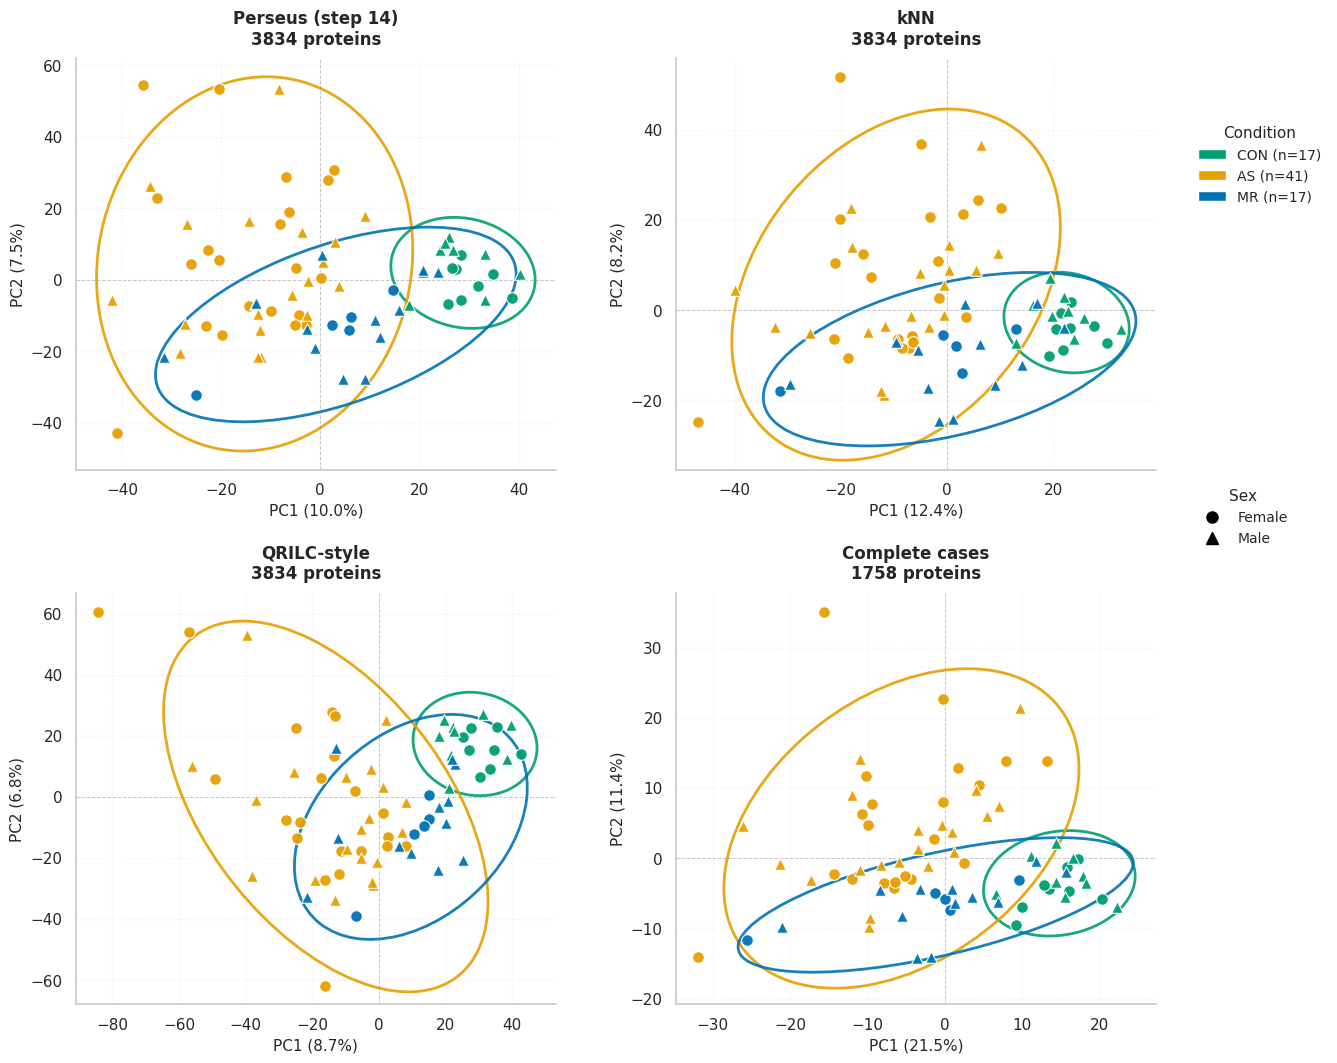

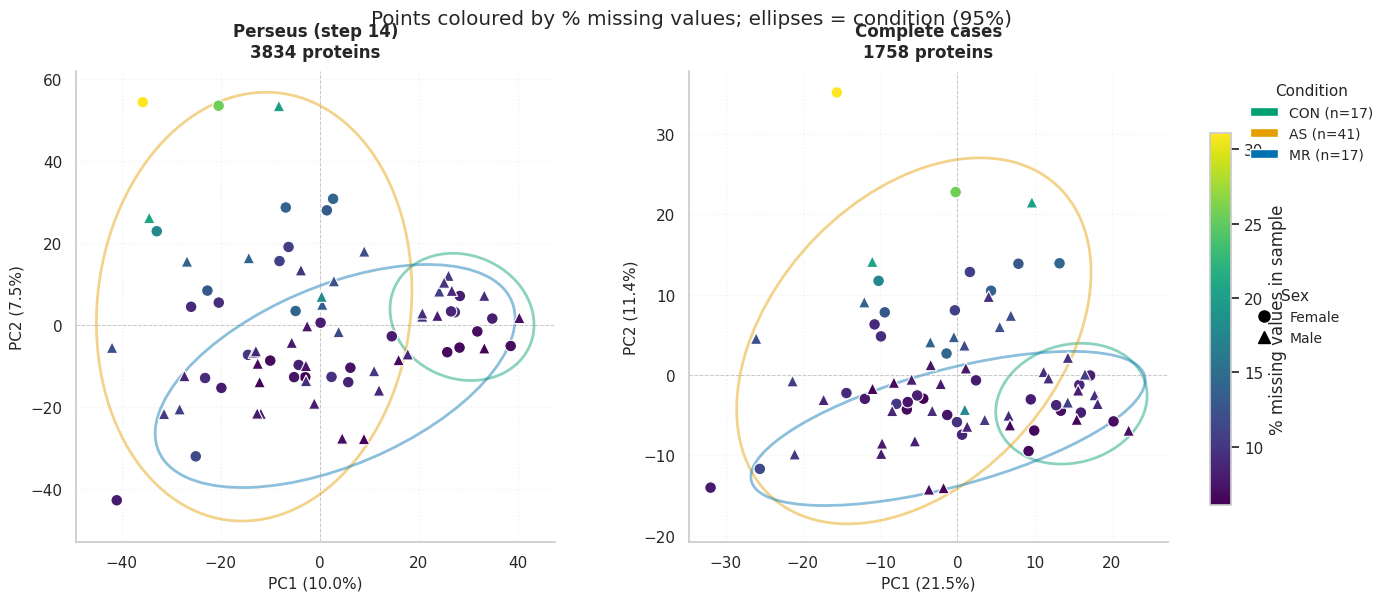


PCA summary (silhouette on PC1-PC2: 1 = perfect separation, 0 = overlap)
analysis            Perseus (step 14)       kNN  QRILC-style  Complete cases
samples                        75.000    75.000       75.000          75.000
proteins                     3834.000  3834.000     3834.000        1758.000
PC1_%                          10.000    12.400        8.700          21.500
PC2_%                           7.500     8.200        6.800          11.400
silhouette_group                0.186     0.190        0.157           0.192
silhouette_sex                  0.001    -0.002        0.001          -0.004
r_PC1_%missing                 -0.410    -0.230       -0.750          -0.160
r_PC2_%missing                  0.760     0.810        0.540           0.810
|r|_PC1_vs_Perseus                NaN     0.960        0.880           0.920
|r|_PC2_vs_Perseus                NaN     0.950        0.870           0.900

Median % missing per sample by condition: {'aortic stenosis': 10.2, 'control (

In [ ]:
# ==================================================================
# PCA comparison across imputation methods (Google Colab)
#
# HOW TO USE
#   1. Run the notebook from the top down to step 14 (imputation).
#      For the flagged-sample panels also run the cell that creates
#      `sample_flags` (step with the Tukey flags); without it those panels
#      are skipped.
#   2. Paste this whole file into ONE new code cell and run it.
#
# What it makes
#   Figure 1  PCA of the same 75 samples under Perseus (step 14), kNN,
#             QRILC-style imputation and complete cases only (no imputation)
#   Figure 2  imputed vs complete-case PCA, points coloured by the % of
#             missing values per sample
#   Figure 3  flagged samples ringed (labelled if >= 2 flags), and the PCA
#             recomputed without them
#   Tables    pca_comparison.csv, sample_covariates.csv (for later models)
#
# Style follows the notebook's PCA cells: colour = condition, marker = sex,
# 95 % group ellipses. The mixed imputation is left out on purpose: its rule
# uses the group labels, which would build group structure into the PCA.
# Needs: log2, log2_imp, meta (and optionally sample_flags, OUT_DIR).
# ==================================================================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, Patch
from scipy import stats
from scipy.stats import chi2
from sklearn.impute import KNNImputer
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore", category=RuntimeWarning)

_missing = [n for n in ["log2", "log2_imp", "meta"] if n not in globals()]
if _missing:
    raise RuntimeError(f"Run the notebook cells above first (missing: {_missing}).")

SEED = 42
SAVE_DIR = OUT_DIR if "OUT_DIR" in globals() else Path(".")

GROUP_ORDER = ["control (donor heart)", "aortic stenosis", "mitral regurgitation"]
GROUP_COLORS = {"control (donor heart)": "#009E73",
                "aortic stenosis": "#E69F00",
                "mitral regurgitation": "#0072B2"}
GROUP_LABELS = {"control (donor heart)": "CON", "aortic stenosis": "AS",
                "mitral regurgitation": "MR"}
SEX_MARKERS = {"female": "o", "male": "^"}

samples = list(log2.columns)
meta_s = meta.loc[samples, ["group", "sex"]]
group_n = meta_s["group"].value_counts()

# % of values per sample that are missing (= imputed in the imputed matrices)
pct_missing = pd.Series(100 * log2.isna().mean(axis=0).to_numpy(), index=samples)

# flags from the notebook (optional)
if "sample_flags" in globals():
    n_flags = sample_flags["n_flags"].reindex(samples).fillna(0).astype(int)
else:
    n_flags = None
    print("`sample_flags` not found: the flagged-sample panels will be skipped.")


# ------------------------------------------------------------------
# 1. The imputed matrices (Perseus is the notebook's own log2_imp)
# ------------------------------------------------------------------
def impute_knn(M, k=10):
    out = KNNImputer(n_neighbors=k).fit_transform(M.to_numpy(float))
    return pd.DataFrame(out, index=M.index, columns=M.columns)


def impute_qrilc(M):
    """Fit the full normal curve from the observed upper part of each sample
    and draw the missing values from its lower tail."""
    rng = np.random.default_rng(SEED)
    X = M.to_numpy(float)
    out = X.copy()
    for j in range(X.shape[1]):
        m = np.isnan(out[:, j])
        if not m.any():
            continue
        obs = np.sort(X[~m, j])
        n_miss, n_obs = m.sum(), len(obs)
        p_miss = n_miss / (n_miss + n_obs)
        probs = p_miss + (1 - p_miss) * (np.arange(1, n_obs + 1) - 0.5) / n_obs
        sd, mu = np.polyfit(stats.norm.ppf(probs), obs, 1)
        upper = stats.norm.ppf(p_miss)                     # cut-off in SD units
        out[m, j] = stats.truncnorm.rvs(-np.inf, upper, loc=mu, scale=sd,
                                        size=n_miss, random_state=rng)
    return pd.DataFrame(out, index=M.index, columns=M.columns)


MATS = {
    "Perseus (step 14)": log2_imp.loc[:, samples],
    "kNN": impute_knn(log2),
    "QRILC-style": impute_qrilc(log2),
    "Complete cases": log2.dropna(),               # no imputation at all
}
for name, M in MATS.items():
    print(f"{name:20} {M.shape[0]:5} proteins x {M.shape[1]} samples")


# ------------------------------------------------------------------
# 2. PCA (each protein centred across samples, as in the notebook)
# ------------------------------------------------------------------
def pca_scores(M, n=5):
    X = M.to_numpy(float)
    X = X - X.mean(axis=1, keepdims=True)
    U, S, _ = np.linalg.svd(X.T, full_matrices=False)
    k = min(n, len(S))
    scores = pd.DataFrame(U[:, :k] * S[:k], index=M.columns,
                          columns=[f"PC{i + 1}" for i in range(k)])
    return scores, 100 * S ** 2 / (S ** 2).sum()


ref_scores, _ = pca_scores(MATS["Perseus (step 14)"])


def align(scores, ref):
    """Flip PC1 / PC2 if needed so axes point the same way as the reference
    (the sign of a principal component is arbitrary)."""
    out, common = scores.copy(), scores.index.intersection(ref.index)
    for pc in ("PC1", "PC2"):
        if np.corrcoef(scores.loc[common, pc], ref.loc[common, pc])[0, 1] < 0:
            out[pc] = -out[pc]
    return out


PCA = {}
for name, M in MATS.items():
    s, v = pca_scores(M)
    PCA[name] = (align(s, ref_scores), v)


# ------------------------------------------------------------------
# 3. Plot helpers (same look as the notebook's PCA cells)
# ------------------------------------------------------------------
def add_ellipse(ax, x, y, color, alpha=0.9):
    pts = np.column_stack([x, y])
    if len(pts) < 3:
        return
    eigvals, eigvecs = np.linalg.eigh(np.cov(pts, rowvar=False))
    idx = np.argsort(eigvals)[::-1]
    eigvals, eigvecs = np.maximum(eigvals[idx], 0), eigvecs[:, idx]
    w, h = 2 * np.sqrt(chi2.ppf(0.95, 2)) * np.sqrt(eigvals)
    ax.add_patch(Ellipse(pts.mean(axis=0), w, h,
                         angle=np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0])),
                         facecolor="none", edgecolor=color, linewidth=2,
                         alpha=alpha, zorder=1))


PCT_RANGE = (float(pct_missing.min()), float(pct_missing.max()))


def draw(ax, scores, var, title, colour_by="group", flags=None):
    sc = scores.join(meta_s)
    for g in GROUP_ORDER:
        sub = sc[sc["group"] == g]
        add_ellipse(ax, sub["PC1"], sub["PC2"], GROUP_COLORS[g],
                    alpha=0.9 if colour_by == "group" else 0.45)
    mappable = None
    for g in GROUP_ORDER:
        for sex, marker in SEX_MARKERS.items():
            sub = sc[(sc["group"] == g) & (sc["sex"] == sex)]
            if colour_by == "group":
                ax.scatter(sub["PC1"], sub["PC2"], color=GROUP_COLORS[g], marker=marker,
                           s=70, edgecolors="white", linewidths=0.8, alpha=0.95, zorder=3)
            else:
                mappable = ax.scatter(sub["PC1"], sub["PC2"], c=pct_missing.loc[sub.index],
                                      cmap="viridis", vmin=PCT_RANGE[0], vmax=PCT_RANGE[1],
                                      marker=marker, s=70, edgecolors="white",
                                      linewidths=0.8, zorder=3)
    if flags is not None:                           # ring flagged samples
        f1 = sc.index[flags.reindex(sc.index).fillna(0) >= 1]
        ax.scatter(sc.loc[f1, "PC1"], sc.loc[f1, "PC2"], s=190, facecolors="none",
                   edgecolors="black", linewidths=1.1, zorder=4)
        for s in sc.index[flags.reindex(sc.index).fillna(0) >= 2]:
            ax.annotate(s, (sc.loc[s, "PC1"], sc.loc[s, "PC2"]), xytext=(6, 6),
                        textcoords="offset points", fontsize=8, zorder=5)
    ax.axhline(0, color="grey", ls="--", lw=0.7, alpha=0.4)
    ax.axvline(0, color="grey", ls="--", lw=0.7, alpha=0.4)
    ax.grid(ls=":", alpha=0.25)
    ax.set_xlabel(f"PC1 ({var[0]:.1f}%)", fontsize=11)
    ax.set_ylabel(f"PC2 ({var[1]:.1f}%)", fontsize=11)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.spines[["top", "right"]].set_visible(False)
    return mappable


def legends(fig, x=0.80, ring=False):
    fig.legend(handles=[Patch(facecolor=GROUP_COLORS[g],
                              label=f"{GROUP_LABELS[g]} (n={group_n[g]})")
                        for g in GROUP_ORDER],
               title="Condition", loc="upper left", bbox_to_anchor=(x, 0.88),
               frameon=False, fontsize=10, title_fontsize=11)
    handles = [Line2D([0], [0], marker=m, color="black", linestyle="None",
                      markersize=8, label=s.capitalize()) for s, m in SEX_MARKERS.items()]
    if ring:
        handles.append(Line2D([0], [0], marker="o", markerfacecolor="none",
                              markeredgecolor="black", markersize=12, linestyle="None",
                              label="flagged (>=1)"))
    fig.legend(handles=handles, title="Sex", loc="upper left",
               bbox_to_anchor=(x, 0.55), frameon=False, fontsize=10, title_fontsize=11)


def title_of(name):
    M = MATS[name]
    return f"{name}\n{M.shape[0]} proteins"


# ------------------------------------------------------------------
# Figure 1: the same samples, four ways of dealing with missing values
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.subplots_adjust(left=0.06, right=0.78, bottom=0.07, top=0.93, wspace=0.25, hspace=0.3)
for ax, name in zip(axes.ravel(), MATS):
    s, v = PCA[name]
    draw(ax, s, v, title_of(name))
legends(fig)
fig.savefig(SAVE_DIR / "PCA_methods_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Figure 2: is a PC just "how many values are missing in this sample"?
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
fig.subplots_adjust(left=0.06, right=0.84, bottom=0.12, top=0.88, wspace=0.28)
for ax, name in zip(axes, ["Perseus (step 14)", "Complete cases"]):
    s, v = PCA[name]
    mp = draw(ax, s, v, title_of(name), colour_by="pct")
cax = fig.add_axes([0.87, 0.18, 0.015, 0.6])
fig.colorbar(mp, cax=cax, label="% missing values in sample")
legends(fig, x=0.89)
fig.suptitle("Points coloured by % missing values; ellipses = condition (95%)", y=0.98)
fig.savefig(SAVE_DIR / "PCA_missingness.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Figure 3: do the flagged samples drive the pattern?
# ------------------------------------------------------------------
if n_flags is not None:
    keep = [s for s in samples if n_flags[s] == 0]
    PCA_noflag = {}
    for name in ("Perseus (step 14)", "Complete cases"):
        M = MATS[name][keep]
        if name == "Complete cases":
            M = log2[keep].dropna()                 # complete cases among the kept samples
        s, v = pca_scores(M)
        PCA_noflag[name] = (align(s, ref_scores), v, M.shape[0])
    fig, axes = plt.subplots(1, 3, figsize=(19, 6.2))
    fig.subplots_adjust(left=0.05, right=0.80, bottom=0.12, top=0.86, wspace=0.28)
    s, v = PCA["Perseus (step 14)"]
    draw(axes[0], s, v, f"Perseus, all {len(samples)} samples\n(flagged ringed)", flags=n_flags)
    for ax, name in zip(axes[1:], PCA_noflag):
        s, v, n_prot = PCA_noflag[name]
        draw(ax, s, v, f"{name}, {len(keep)} unflagged samples\n{n_prot} proteins")
    legends(fig, x=0.82, ring=True)
    fig.savefig(SAVE_DIR / "PCA_flagged_samples.png", dpi=300, bbox_inches="tight")
    plt.show()


# ------------------------------------------------------------------
# Numbers behind the plots
# ------------------------------------------------------------------
def summarise(label, scores, var, n_prot, ref=None):
    idx = scores.index
    grp, sex = meta_s.loc[idx, "group"], meta_s.loc[idx, "sex"]
    xy = scores[["PC1", "PC2"]].to_numpy()
    row = {"analysis": label, "samples": len(idx), "proteins": n_prot,
           "PC1_%": round(var[0], 1), "PC2_%": round(var[1], 1),
           "silhouette_group": round(silhouette_score(xy, grp), 3),
           "silhouette_sex": round(silhouette_score(xy, sex), 3),
           "r_PC1_%missing": round(np.corrcoef(scores["PC1"], pct_missing.loc[idx])[0, 1], 2),
           "r_PC2_%missing": round(np.corrcoef(scores["PC2"], pct_missing.loc[idx])[0, 1], 2)}
    if ref is not None:
        row["|r|_PC1_vs_Perseus"] = round(abs(np.corrcoef(scores["PC1"], ref["PC1"])[0, 1]), 2)
        row["|r|_PC2_vs_Perseus"] = round(abs(np.corrcoef(scores["PC2"], ref["PC2"])[0, 1]), 2)
    return row


rows = [summarise(name, PCA[name][0], PCA[name][1], MATS[name].shape[0],
                  None if name == "Perseus (step 14)" else ref_scores)
        for name in MATS]
if n_flags is not None:
    for name, (s, v, n_prot) in PCA_noflag.items():
        rows.append(summarise(f"{name}, flagged removed", s, v, n_prot))
table = pd.DataFrame(rows).set_index("analysis")
print("\nPCA summary (silhouette on PC1-PC2: 1 = perfect separation, 0 = overlap)")
print(table.T.to_string())
table.to_csv(SAVE_DIR / "pca_comparison.csv")

# is missingness tied to condition or sex? (matters for the later models)
cov = pd.DataFrame({"group": meta_s["group"], "sex": meta_s["sex"],
                    "pct_missing": pct_missing.round(2)})
if n_flags is not None:
    cov["n_flags"] = n_flags
cov.to_csv(SAVE_DIR / "sample_covariates.csv")
print("\nMedian % missing per sample by condition:",
      cov.groupby("group")["pct_missing"].median().round(1).to_dict())
kw = stats.kruskal(*[cov.loc[cov["group"] == g, "pct_missing"] for g in GROUP_ORDER])
print(f"Kruskal-Wallis across conditions: p = {kw.pvalue:.3g}")
mw = stats.mannwhitneyu(cov.loc[cov["sex"] == "female", "pct_missing"],
                        cov.loc[cov["sex"] == "male", "pct_missing"])
print(f"Female vs male: p = {mw.pvalue:.3g}")
print("\nSaved:", ", ".join(["PCA_methods_comparison.png", "PCA_missingness.png",
                              *(["PCA_flagged_samples.png"] if n_flags is not None else []),
                              "pca_comparison.csv", "sample_covariates.csv"]), "in", SAVE_DIR)
print("For later models, pct_missing can enter as a covariate, e.g. in limma: "
      "design = ~ 0 + group_sex + pct_missing")